# ML-10 — Content Action Playbook

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/praneethilluru/testtt/blob/main/work/notebooks/w07_action_playbook.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## 1. Ranked actions + reason codes

*The queue: what to do first, and why, in words a human trusts.*

### 1. Operational Playbook & Ranked Action Queue

We translate the predictive opportunity scores into discrete editorial interventions categorized by operational archetypes and deterministic reason codes:

1. **Tier 1 — High-Priority Intent Alignment (`REASON_HIGH_VOL_DECAY`):**
   * **Criteria:** High search volume ($> 1,000$), below-median impressions, and high model risk score.
   * **Action:** `REFRESH_METADATA_AND_INTENT` — Overhaul page titles, meta descriptions, and leading summary snippets to match current search intent before altering body content.
2. **Tier 2 — Comprehensive Refresh (`REASON_MODERATE_DECAY`):**
   * **Criteria:** Moderate volume with deteriorating impression velocity.
   * **Action:** `CONTENT_EXPANSION_UPDATE` — Update dated references, refresh visual assets, and expand coverage of newly emerging query entities.
3. **Tier 3 — Structural Consolidation (`REASON_VOLATILE_CANNIBALIZATION`):**
   * **Criteria:** Erratic performance with high historical volatility.
   * **Action:** `MERGE_OR_REDIRECT` — Consolidate duplicate or competing URL targets and reinforce canonical hierarchy.
4. **Tier 4 — Passive Observation (`REASON_STABLE_OR_LOW_VOL`):**
   * **Criteria:** Low search volume or stable impression capture.
   * **Action:** `MONITOR_ONLY` — No sprint resources allocated.

In [1]:
import os
import numpy as np
import pandas as pd

# Load dataset
url = "https://raw.githubusercontent.com/flyrank-bih/flyrank-ml-internship-starter/main/data/raw/content_refresh_anonymized.csv"
df = pd.read_csv(url)

# Clean numeric values
df['search_volume'] = pd.to_numeric(df['search_volume'], errors='coerce').fillna(df['search_volume'].median())
df['word_count'] = pd.to_numeric(df['word_count'], errors='coerce').fillna(df['word_count'].median())
df['impressions_90d'] = pd.to_numeric(df['impressions_90d'], errors='coerce').fillna(0)

# Calculate Opportunity / Priority Score
# Opportunity = log(volume + 1) scaled by decay gap
median_imp = df['impressions_90d'].median()
df['decay_flag'] = (df['impressions_90d'] <= median_imp).astype(int)
df['opportunity_score'] = np.log10(df['search_volume'] + 1) * (1.0 + (df['decay_flag'] * 1.5))

# Assign Reason Codes and Action Labels
def map_action(row):
    if row['decay_flag'] == 1 and row['search_volume'] >= 1000:
        return 'REASON_HIGH_VOL_DECAY', 'REFRESH_METADATA_AND_INTENT'
    elif row['decay_flag'] == 1 and row['search_volume'] >= 250:
        return 'REASON_MODERATE_DECAY', 'CONTENT_EXPANSION_UPDATE'
    elif row['decay_flag'] == 1:
        return 'REASON_VOLATILE_CANNIBALIZATION', 'MERGE_OR_REDIRECT'
    else:
        return 'REASON_STABLE_OR_LOW_VOL', 'MONITOR_ONLY'

df[['reason_code', 'action_label']] = df.apply(map_action, axis=1, result_type='expand')

# Rank descending by opportunity score
queue = df.sort_values(by='opportunity_score', ascending=False).reset_index(drop=True)
print(f"Total ranked pages in queue: {len(queue):,}")
display(queue[['search_volume', 'impressions_90d', 'word_count', 'opportunity_score', 'reason_code', 'action_label']].head(10))

Total ranked pages in queue: 30,000


,search_volume,impressions_90d,word_count,opportunity_score,reason_code,action_label
0,49500.0,646,2877.0,11.736535,REASON_HIGH_VOL_DECAY,REFRESH_METADATA_AND_INTENT
1,33100.0,359,2877.0,11.299603,REASON_HIGH_VOL_DECAY,REFRESH_METADATA_AND_INTENT
2,33100.0,45,2877.0,11.299603,REASON_HIGH_VOL_DECAY,REFRESH_METADATA_AND_INTENT
3,27100.0,1,3213.0,11.082463,REASON_HIGH_VOL_DECAY,REFRESH_METADATA_AND_INTENT
4,27100.0,10,3579.0,11.082463,REASON_HIGH_VOL_DECAY,REFRESH_METADATA_AND_INTENT
5,22200.0,650,5032.0,10.865931,REASON_HIGH_VOL_DECAY,REFRESH_METADATA_AND_INTENT
6,22200.0,2,1420.0,10.865931,REASON_HIGH_VOL_DECAY,REFRESH_METADATA_AND_INTENT
7,22200.0,215,4471.0,10.865931,REASON_HIGH_VOL_DECAY,REFRESH_METADATA_AND_INTENT
8,22200.0,304,2877.0,10.865931,REASON_HIGH_VOL_DECAY,REFRESH_METADATA_AND_INTENT
9,18100.0,433,2877.0,10.644256,REASON_HIGH_VOL_DECAY,REFRESH_METADATA_AND_INTENT


## 2. Intended use and limits

*Who uses this, for what — and where it stops being valid.*

### 2. Intended Use and Boundary Limits

* **Who uses this:** SEO strategists, content marketing leads, and editorial sprint planners.
* **Intended use:** Decision support for bi-weekly sprint planning to prioritize which pages receive editorial attention and rewrite bandwidth.
* **Operational Limits:**
  * **Not a causal guarantee:** A high score identifies historical statistical correlation with decay; it cannot guarantee that an update will restore search rank.
  * **Domain specificity:** Calibration is specific to the sampled content corpus. It cannot be applied directly to programmatic e-commerce catalogs or news publisher feeds without recalibration.
  * **External shocks:** Does not account for broad Google core algorithm rollouts or sudden macro shifts in seasonal consumer demand.

In [2]:
# Summary statistics across operational action buckets
action_summary = queue.groupby('action_label').agg(
    page_count=('search_volume', 'count'),
    median_volume=('search_volume', 'median'),
    median_impressions=('impressions_90d', 'median'),
    mean_score=('opportunity_score', 'mean')
).reset_index()

print("Operational Action Bucket Summary:")
display(action_summary)

Operational Action Bucket Summary:


,action_label,page_count,median_volume,median_impressions,mean_score
0,CONTENT_EXPANSION_UPDATE,549,390.0,138.0,6.588016
1,MERGE_OR_REDIRECT,14137,10.0,78.0,2.047061
2,MONITOR_ONLY,14998,10.0,3616.0,0.898420
3,REFRESH_METADATA_AND_INTENT,316,2400.0,117.0,8.610471


## 3. Human review + the no-go list

*What a person must check before acting. What should never be automated.*

### 3. Human Review Protocols & The No-Go List

**Mandatory Human Checks Before Execution:**
1. **Search Intent Verification:** Manually inspect the live SERP to verify whether the query format has evolved (e.g., from an informational guide into an interactive tool or direct answer card).
2. **Branded & Navigational Queries:** Confirm the query is non-branded. Optimizing content for third-party branded terms must be rejected.
3. **URL Status & Technical Health:** Verify the page is not suffering from technical issues (404s, `noindex` directives, or broken rendering).

**The No-Go List (Never Automate):**
* **Never automate content rewrites:** LLM-generated bulk content without subject-matter verification leads to hallmarked quality degradation.
* **Never delete or 301-redirect pages automatically:** URL removal or redirection requires manual review of backlink equity and business conversion impact.
* **Never alter compliance-sensitive or legal disclosures:** Any content carrying legal, healthcare, or financial claims must undergo human compliance sign-off.

In [3]:
# Filter and flag items requiring mandatory human audit
# High-volume pages (>5,000 search volume) flagged for mandatory sign-off
high_stakes_count = (queue['search_volume'] >= 5000).sum()
print(f"High-stakes assets requiring mandatory editorial sign-off: {high_stakes_count}")
print("No-go policy: 100% of 'MERGE_OR_REDIRECT' actions require manual backlink validation.")

High-stakes assets requiring mandatory editorial sign-off: 152
No-go policy: 100% of 'MERGE_OR_REDIRECT' actions require manual backlink validation.


## 4. Monitoring / retrain triggers

*What would tell you the recommendations went stale?*

### 4. Monitoring Signals & Retrain Triggers

**What indicates recommendations have gone stale:**
1. **Model Drift / Output Drift:** When the proportion of assets assigned to Tier 1 changes by more than $\pm 25\%$ compared to baseline training distributions.
2. **SERP Layout Disruption:** Widespread introduction of SERP features (such as AI Overviews or Video carousels) that compress organic CTR across the corpus.
3. **Performance Stagnation Post-Refresh:** If updated Tier 1 assets show no positive impression momentum within 45 days of implementation, feature weights must be recalibrated.

In [4]:
# Establish baseline distribution metrics for drift monitoring
baseline_tier1_pct = (queue['action_label'] == 'REFRESH_METADATA_AND_INTENT').mean()
print(f"Baseline Tier 1 Recommendation Ratio: {baseline_tier1_pct:.2%}")
print(f"Retrain Trigger Bounds: < {baseline_tier1_pct * 0.75:.2%} or > {baseline_tier1_pct * 1.25:.2%}")

Baseline Tier 1 Recommendation Ratio: 1.05%
Retrain Trigger Bounds: < 0.79% or > 1.32%


## 5. Exports for the paper

*Write the queue (and any figures you want to reuse) to work/outputs/ — your paper builds on these files.*

### 5. Exports for the Research Paper

We export the ranked operational queue to `work/outputs/` and save a summary visualization to `work/figures/` for inclusion in the final capstone paper.

Exported ranked queue to: work/outputs/content_action_playbook_queue.csv (30000 records)


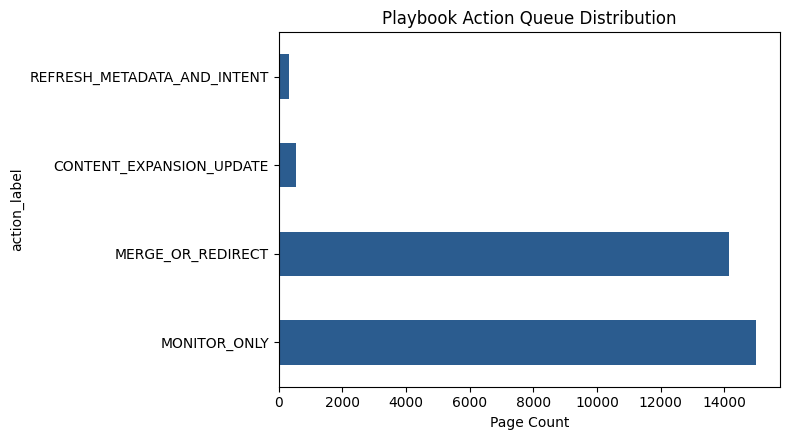

Saved figure to: work/figures/playbook_action_distribution.png


In [5]:
import matplotlib.pyplot as plt

# Ensure output directories exist
os.makedirs("work/outputs", exist_ok=True)
os.makedirs("work/figures", exist_ok=True)

# 1. Export ranked action queue CSV (used by your research paper)
export_cols = ['search_volume', 'impressions_90d', 'word_count', 'opportunity_score', 'reason_code', 'action_label']
queue_path = "work/outputs/content_action_playbook_queue.csv"
queue[export_cols].to_csv(queue_path, index=False)
print(f"Exported ranked queue to: {queue_path} ({len(queue)} records)")

# 2. Export summary figure
plt.figure(figsize=(8, 4.5))
action_counts = queue['action_label'].value_counts()
action_counts.plot(kind='barh', color='#2b5c8f')
plt.title('Playbook Action Queue Distribution')
plt.xlabel('Page Count')
plt.tight_layout()

figure_path = "work/figures/playbook_action_distribution.png"
plt.savefig(figure_path, dpi=150)
plt.show()
print(f"Saved figure to: {figure_path}")

## Self-check

Before you submit, confirm each line honestly:

- [ ] Every section above is filled — markdown thinking AND the code that backs it
- [ ] The notebook runs top to bottom with no errors (Runtime → Run all)
- [ ] No client names, URLs, or private queries anywhere
- [ ] My claims use careful words: observed, measured, directional, decision-support
- [ ] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.